# 01 — Preprocessing · Wang et al. 2019 (Glioblastoma, 10x)

Load malignant cells → threshold under-populated samples (data-derived count gap) → gene filter → overdispersed selection → PCA (no scaling) → Harmony on `sample` → neighbors → UMAP → Leiden → drop detached islands → annotate GBM cell states (Neftel meta-programs + data-derived markers).

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
np.random.seed(0)

In [2]:
# custom 3CA dataloader
pth_scripts = os.path.join('..', '..', '..', '..', '..', '..', 'cancer', 'vertebrate', 'CCCA')
sys.path.append(pth_scripts)
from scripts.load import load_CCCA_adata

In [3]:
# resolve paths — notebooks live two levels deeper than Puram (Claude/<Category>/<Dataset-N>/)
name = os.path.split(os.getcwd())[1]                            # Wang2019_Brain-5
dataname = name.rsplit('-', 1)[0]                               # Wang2019_Brain
category = os.path.split(os.path.split(os.getcwd())[0])[1]      # Brain
pth = os.path.join(*(['..'] * 6))                              # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{dataname}')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load dataset → select malignant cells

In [4]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
adata.var_names_make_unique()
# shipped cell-cycle columns are empty for this dataset -> drop (recomputed below)
for c in ['g1s_score', 'g2m_score', 'cell_cycle_phase']:
    if c in adata.obs.columns: del adata.obs[c]
adata

Loading ../../../../../../data/unzip/CCCA/Data_Wang2019_Brain
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
Done.


AnnData object with n_obs × n_vars = 9916 × 33545
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype'
    uns: 'log1p'

### Inspect per-sample malignant counts → threshold at the largest count gap
Depth-invariant rule: rank samples by count, take the largest successive ratio drop as the inflection, keep samples above it (derived, not the anchor's hardcoded ≥100).

In [5]:
n = adata.obs['sample'].value_counts().sort_values(ascending=False)
counts = n.values
ratios = counts[:-1] / counts[1:]
gap = int(np.argmax(ratios))
thr = int(counts[gap])
print('per-sample counts:\n', n)
print('\nsuccessive ratios:', np.round(ratios, 2))
print(f'largest gap after rank {gap}: {counts[gap]} -> {counts[gap+1]} (ratio {ratios[gap]:.2f})')
print(f'threshold: keep samples with >= {thr} malignant cells')

per-sample counts:
 sample
SF4297       2732
SF10022      2492
SF12264      1293
SF6996       1112
SF10127       938
SF11979sn     687
SF4400        396
SF9259R       143
SF9259S        85
SF12090        38
Name: count, dtype: int64

successive ratios: [1.1  1.93 1.16 1.19 1.37 1.73 2.77 1.68 2.24]
largest gap after rank 6: 396 -> 143 (ratio 2.77)
threshold: keep samples with >= 396 malignant cells


In [6]:
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
adata.obs['sample'] = adata.obs['sample'].astype('category')
print(f'kept {len(keep)}/{len(n)} samples -> {adata.n_obs} cells')
adata

kept 7/10 samples -> 9650 cells


AnnData object with n_obs × n_vars = 9650 × 33545
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype'
    uns: 'log1p'

### Gene filter → overdispersed feature selection

In [7]:
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var['highly_variable'].sum()))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2113 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2113


### PCA → Harmony integration on `sample`
No `sc.pp.scale` before PCA (absent from the reference protocol). Harmony `theta` chosen by the integration sweep below; `theta=10` gives the best patient mixing for this 10x set.

In [8]:
sc.pp.pca(adata, n_comps = 50, use_highly_variable = True)
sce.pp.harmony_integrate(adata, 'sample', theta = 10, max_iter_harmony = 20)

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:438: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)
2026-08-08 04:04:14,087 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 04:04:15,203 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 04:04:15,253 - harmonypy - INFO - Iteration 1 of 20
2026-08-08 04:04:17,236 - harmonypy - INFO - Iteration 2 of 20
2026-08-08 04:04:19,183 - harmonypy - INFO - Iteration 3 of 20
2026-08-08 04:04:21,098 - harmonypy - INFO - Iteration 4 of 20
2026-08-08 04:04:23,021 - harmonypy - INFO - Iteration 5 of 20
2026-08-08 04:04:24,942 - harmonypy - INFO - Iteration 6 of 20
2026-08-08 04:04:26,880 - harmonypy - INFO - Iteration 7 of 20
2026-08-08 

### Integration sweep — Gate 1 evidence (mixing)
iLISI (inverse-Simpson on `sample` within each cell's neighborhood; 1 = patient-private, up to n_samples = fully mixed) pre- vs post-Harmony across `n_pcs`. Gate 1 is judged on the **embedding** (next cell); this only corroborates.

In [9]:
from sklearn.neighbors import NearestNeighbors
def ilisi(emb, labels, k = 90):
    lab = pd.Categorical(labels); codes = lab.codes; nc = len(lab.categories)
    idx = NearestNeighbors(n_neighbors = k + 1).fit(emb).kneighbors(emb, return_distance = False)[:, 1:]
    vals = [1.0 / np.sum((np.bincount(codes[idx[i]], minlength = nc) / k) ** 2) for i in range(emb.shape[0])]
    return np.median(vals)
samp = adata.obs['sample'].values
print('pre-Harmony       n_pcs=20: iLISI = %.2f' % ilisi(adata.obsm['X_pca'][:, :20], samp))
for npc in [20, 30, 40]:
    print('Harmony theta=10  n_pcs=%d: iLISI = %.2f' % (npc, ilisi(adata.obsm['X_pca_harmony'][:, :npc], samp)))

pre-Harmony       n_pcs=20: iLISI = 1.00
Harmony theta=10  n_pcs=20: iLISI = 2.35
Harmony theta=10  n_pcs=30: iLISI = 2.22
Harmony theta=10  n_pcs=40: iLISI = 2.17


### Neighbors → UMAP → visual inspection (Gate 1: mixing + continuity)
`n_pcs=20` (10x precedent; not a naive elbow). The embedding is inspected for sample mixing and a single connected continuous manifold — the decisive Gate-1 read.

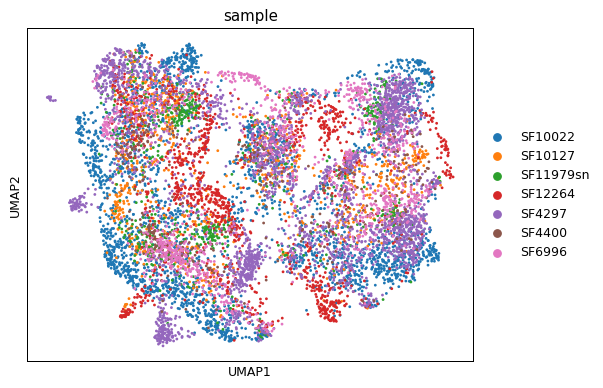

In [10]:
sc.pp.neighbors(adata, n_pcs = 20, n_neighbors = 30, use_rep = 'X_pca_harmony')
sc.tl.umap(adata, spread = 1.3, random_state = 0)
sc.pl.umap(adata, color = ['sample'], size = 20)

### Leiden clustering → detached-island removal
A UMAP radius graph (6× median nearest-neighbour distance) → connected components → keep the largest. Strips only disconnected specks; the bulk manifold is one component.

In [11]:
sc.tl.leiden(adata, resolution = 1.0, random_state = 0, flavor = 'igraph', n_iterations = 2, directed = False)
from scipy.sparse.csgraph import connected_components
from scipy.sparse import csr_matrix
U = adata.obsm['X_umap']
d = NearestNeighbors(n_neighbors = 2).fit(U).kneighbors(U)[0][:, 1]
G = NearestNeighbors(radius = 6 * np.median(d)).fit(U).radius_neighbors_graph(U)
ncomp, lab = connected_components(csr_matrix(G), directed = False)
big = pd.Series(lab).value_counts().index[0]
print(f'radius-graph components = {ncomp}; detached island cells = {(lab != big).sum()}')
adata = adata[lab == big].copy()
adata

radius-graph components = 10; detached island cells = 34


AnnData object with n_obs × n_vars = 9616 × 26409
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'sample_colors', 'leiden'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

### Cell-state annotation — Neftel GBM meta-programs + data-derived markers
No molecular subtype split for this dataset; malignant cells are annotated to canonical GBM states (Neftel et al. 2019 — also carried in the 3CA `mp_top` field) scored from data-derived markers, and each Leiden cluster is labelled by its top-scoring state.

celltype
NPC-like    4760
AC-like     2814
MES-like    2042
Name: count, dtype: int64


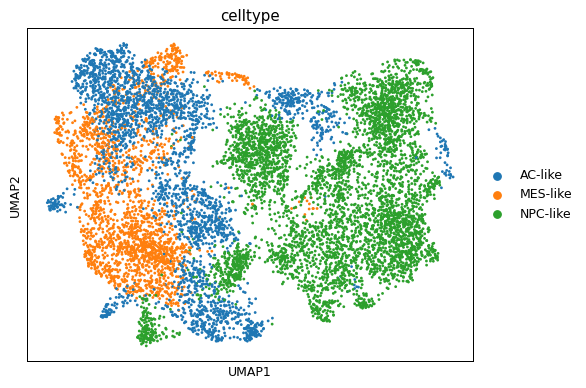

In [12]:
markers = {'AC-like':  ['GFAP', 'AQP4', 'CLU', 'CST3'],
           'MES-like': ['CHI3L1', 'CD44', 'ANXA1', 'VIM'],
           'NPC-like': ['DLL3', 'SOX4', 'STMN2', 'DCX'],
           'OPC-like': ['OLIG1', 'OLIG2', 'PDGFRA', 'APOD']}
for st, mk in markers.items():
    sc.tl.score_genes(adata, [m for m in mk if m in adata.var_names], score_name = 'sc_' + st)
cl_state = {}
for cl in adata.obs['leiden'].cat.categories:
    m = adata.obs['leiden'] == cl
    cl_state[cl] = max(markers, key = lambda s: adata.obs.loc[m, 'sc_' + s].mean())
adata.obs['celltype'] = adata.obs['leiden'].map(cl_state).astype('category')
print(adata.obs['celltype'].value_counts())
sc.pl.umap(adata, color = 'celltype', size = 20)

### Compute cell cycle (shipped annotation empty) — used for lobe-scoping in 02

In [13]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes = [g for g in s_genes if g in adata.var_names], g2m_genes = [g for g in g2m_genes if g in adata.var_names])
adata.obs['cyc_score'] = adata.obs[['S_score', 'G2M_score']].max(axis = 1)
print(adata.obs['phase'].value_counts())

phase
G1     7312
G2M    1505
S       799
Name: count, dtype: int64


### Save processed data

In [14]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('wrote', os.path.join(pth_out, 'processed.h5ad'), adata.shape)

wrote ../../../../../../data/cancer/vertebrate/CCCA/Claude/Brain/Wang2019_Brain-5/processed.h5ad (9616, 26409)


### Deliverable figure — sample integration (Gate 1)

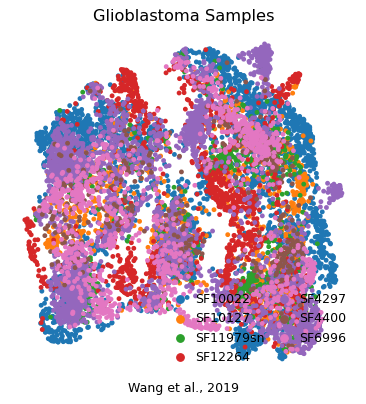

In [15]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'sample', size = 60, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol = 2, frameon = False, loc = 'lower right', columnspacing = .5, handletextpad = .25)
ax.set_title('Glioblastoma Samples', size = 13)
ax.text(.5, -.05, 'Wang et al., 2019', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches = 'tight')